<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 2: Clean and pre-process the data</h1>

<p>Here we clean and pre-process train.csv for modelling. We build on the findings from Task 1 and do not repeat the analysis from there.</p>

<h2>Contents</h2>

<ol>
  <li><a href="#setup">Setup and import</a></li>
  <li><a href="#quality">Missing values and implausible values</a></li>
  <li><a href="#categorical">Categorical variables</a></li>
  <li><a href="#clientes">The optional table clientes.csv</a></li>
  <li><a href="#features">Variables and new features</a></li>
  <li><a href="#scaling">Scaling</a></li>
  <li><a href="#pipeline">Pre-processing function and comparison</a></li>
  <li><a href="#sklearn_pipeline">Pipeline in preprocessing.py</a></li>
  <li><a href="#cleaninglog">Cleaning log</a></li>

</ol>

</div>


<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and import</h2>

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

import sys
import warnings
from pathlib import Path

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from course_helpers import CleaningLog
from preprocessing import preprocessor

sns.set_theme(style="whitegrid")
# hide warnings --> but is checked in Section 7
warnings.filterwarnings("ignore")

# nicer column names for tables 
def label(name):
    name = {"typical_gap_le_90": "typical gap at most 90 days"}.get(name, name)
    text = " ".join(str(name).replace("_", " ").split())
    return text[0].upper() + text[1:]

RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"

In [2]:
trainraw = pd.read_csv("train.csv")
clientes = pd.read_csv("clientes.csv")
print("train", trainraw.shape, " clientes", clientes.shape)

train (6534, 39)  clientes (1143, 13)


<a id="quality"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. Missing values and implausible values</h2>

<h3>2.1 Empty rows</h3>

</div>

In [3]:
# all columns except ID, customer_id and target
featurecols = [c for c in trainraw.columns if c not in ["ID", "customer_id", TARGET]]

# number of missing features per row
missingperrow = trainraw[featurecols].isna().sum(axis=1)

# empty row = all features missing
empty = missingperrow == len(featurecols)

# how many rows miss how many features
missingcounts = (missingperrow.value_counts().sort_index()
                 .rename_axis("Missing features per row").to_frame("Rows"))
missingcounts["Share"] = (missingcounts["Rows"] / len(trainraw)).map("{:.1%}".format)
display(missingcounts)

,Rows,Share
Missing features per row,,
0,3929,60.1%
1,1287,19.7%
2,190,2.9%
3,354,5.4%
4,100,1.5%
5,6,0.1%
7,511,7.8%
8,86,1.3%
9,6,0.1%


In [4]:
# drop the empty rows
train = trainraw[~empty].reset_index(drop=True)
X = train.drop(columns=[TARGET])
y = train[TARGET]
groups = train["customer_id"]

pd.Series({
    "Rows left": len(train),
    "Customers": groups.nunique(),
    "Repeat rate": round(y.mean(), 3),
}, name="Value", dtype=object).rename_axis("Check").to_frame()

,Value
Check,
Rows left,6469
Customers,607
Repeat rate,0.56


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<ul>
  <li><b>60%</b> of the rows have no missing value</li> <li> 511 rows miss exactly 7 values --> probably first purchases, where the 7 history columns are missing (Task 1, 5.3)</li>
  <li>We drop the <b>65 empty rows</b> from train </li>
  <li>There are no other duplicates (Task 1, 5.2), so nothing else is dropped</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>2.2 Repair of the implausible values</h3>



</div>

In [5]:
def repair(df):
    df = df.copy()
    k = df["prior_purchase_count"]
    total = df["prior_total_spend"]

    # -4 days is a code --> missing
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        df.loc[df[col] < 0, col] = np.nan

    # recompute the mean as total / count
    df["prior_mean_purchase_value"] = np.nan
    df.loc[k > 0, "prior_mean_purchase_value"] = total / k

    # max bigger than total is not possible --> missing
    df.loc[df["prior_max_purchase_value"] > total + 0.01, "prior_max_purchase_value"] = np.nan

    # fix spend_365d: remove 1e9, remove the minus, remove values above the total
    df.loc[df["spend_365d"] >= 1e8, "spend_365d"] = np.nan
    df["spend_365d"] = df["spend_365d"].abs()
    df.loc[df["spend_365d"] > total + 0.01, "spend_365d"] = np.nan
    return df

In [6]:
# count each problem
def countproblems(df):
    total = df["prior_total_spend"]
    return pd.Series({
        "Placeholder 1e9": ((df["prior_mean_purchase_value"] >= 1e8) | (df["spend_365d"] >= 1e8)).sum(),
        "Negative amount": ((df["prior_mean_purchase_value"] < 0) | (df["spend_365d"] < 0)).sum(),
        "Day code of minus 4": ((df["days_since_previous_purchase"] < 0) | (df["prior_mean_gap_days"] < 0)).sum(),
        "Wrong mean": ((df["prior_mean_purchase_value"] - total / df["prior_purchase_count"]).abs() > 0.02).sum(),
        "Max above total": (df["prior_max_purchase_value"] > total + 0.01).sum(),
        "Min above max": (df["prior_min_purchase_value"] > df["prior_max_purchase_value"] + 0.01).sum(),
        "Spend 365 days above total": ((df["spend_365d"] > total + 0.01) & (df["spend_365d"] < 1e8)).sum(),
    })

# before and after repair
Xrepaired = repair(X)
pd.DataFrame({"Before": countproblems(X), "After": countproblems(Xrepaired)}).rename_axis("Problem")

,Before,After
Problem,,
Placeholder 1e9,31,0
Negative amount,31,0
Day code of minus 4,32,0
Wrong mean,78,0
Max above total,45,0
Min above max,0,0
Spend 365 days above total,39,0


In [7]:
neg = X["spend_365d"] < 0
allinwindow = neg & (X["purchase_count_365d"] == X["prior_purchase_count"])

signcheck = pd.Series({
    "Negative spend 365 days": neg.sum(),
    "Absolute value at least spend 180 days": (X.loc[neg, "spend_365d"].abs() >= X.loc[neg, "spend_180d"]).sum(),
    "All earlier purchases inside the 365 day window": allinwindow.sum(),
    "Absolute value equal to prior total spend": np.isclose(X.loc[allinwindow, "spend_365d"].abs(),
                                                            X.loc[allinwindow, "prior_total_spend"]).sum(),
}, name="Rows").rename_axis("Check")
signcheck.to_frame()

,Rows
Check,
Negative spend 365 days,15
Absolute value at least spend 180 days,15
All earlier purchases inside the 365 day window,3
Absolute value equal to prior total spend,3


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>After the repair <b>no implausible value is left</b></li>
  <li>The mean purchase value is <b>recomputed</b> as total / count,</li>
 <li>Negative spend_365d: only the <b>sign is wrong</b> (all 15 checks pass) --> we keep the value without the minus</li>
  <li>All other broken values are set to <b>NaN</b> </li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>2.3 Extreme values</h3>

</div>

In [8]:
zerocost = Xrepaired["Custo"] == 0
# cost checks and repeat rates
costcheck = pd.Series({
    "Rows with cost 0": zerocost.sum(),
    "Repeat rate with cost 0": round(y[zerocost].mean(), 3),
    "Repeat rate overall": round(y.mean(), 3),
    "Rows with cost above net total": (Xrepaired["Custo"] > Xrepaired["Total Liquido"]).sum(),
    "AUC of prior total spend": round(roc_auc_score(y, Xrepaired["prior_total_spend"]), 3),
}, name="Value", dtype=object).rename_axis("Check")
display(costcheck.to_frame())

# IQR rule on the total spend
q1, q3 = Xrepaired["prior_total_spend"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outlier = Xrepaired["prior_total_spend"] > upper

# how often do outliers repeat?
outliercheck = pd.DataFrame({
    "Rows": [outlier.sum(), (~outlier).sum()],
    "Share": [f"{outlier.mean():.1%}", f"{(~outlier).mean():.1%}"],
    "Repeat rate": [round(y[outlier].mean(), 3), round(y[~outlier].mean(), 3)],
}, index=["Above IQR bound", "Below IQR bound"])
display(outliercheck)

,Value
Check,
Rows with cost 0,486
Repeat rate with cost 0,0.677
Repeat rate overall,0.56
Rows with cost above net total,39
AUC of prior total spend,0.693


,Rows,Share,Repeat rate
Above IQR bound,642,9.9%,0.841
Below IQR bound,5827,90.1%,0.529


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<ul>
  <li>High amounts are <b>real big customers</b> (Task 1, 5.6) --> more spend means more repeats (AUC 0.693)</li>
  <li>The 642 outliers repeat <b>0.84 vs 0.53</b> --> we <b>keep</b> them and use a log transform</li>
  <li>Cost 0 (486) and below cost (39) can be promotions --> we keep them and add a <b>zero cost flag</b> (repeat 0.68 vs 0.56)</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>2.4 Missing values</h3>


</div>

In [9]:
# number of earlier purchases needed so that the value exists
NEEDED = {"days_since_previous_purchase": 1, "prior_mean_purchase_value": 1,
          "prior_min_purchase_value": 1, "prior_max_purchase_value": 1,
          "prior_std_purchase_value": 2, "prior_mean_gap_days": 2, "prior_std_gap_days": 3}

# fill values that can not exist 
def fillstructural(df):
    df = df.copy()
    k = df["prior_purchase_count"]
    for col, needed in NEEDED.items():
        df.loc[k < needed, col] = 0                    # too few purchases --> 0
    df.loc[k == 0, "spend_365d"] = 0                   # first purchase --> no spend
    df["is_first_purchase"] = (k == 0).astype(int)     # 1= first purchase
    df["has_gap_history"] = (k >= 2).astype(int)       # 1= at least 2 earlier purchases
    return df

# fill the remaining gaps 
def fillmissing(train, test, plan):
    train, test = train.copy(), test.copy()
    for columns, imputer in plan:
        kind = float if all(pd.api.types.is_numeric_dtype(train[c]) for c in columns) else object
        blocks = [half[columns].astype(kind) for half in (train, test)]
        imputer.fit(blocks[0])                        # learn on train only
        train[columns] = imputer.transform(blocks[0])
        test[columns] = imputer.transform(blocks[1])
    return train, test

In [10]:
Xfilled = fillstructural(Xrepaired)
missing = pd.DataFrame({"After repair": Xrepaired.isna().sum(),
                        "After structural fill": Xfilled[Xrepaired.columns].isna().sum()})
missing[missing["After repair"] > 0].sort_values("After repair", ascending=False).rename(index=label).rename_axis("Variable")

,After repair,After structural fill
Variable,,
Prior std gap days,1413,0
Prior mean gap days,1259,211
Prior std purchase value,1048,0
Days since previous purchase,812,209
Prior max purchase value,648,45
Prior mean purchase value,603,0
Prior min purchase value,603,0
Spend 365d,250,231
Transport method,196,196


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Most gaps are <b>structural</b> (too few earlier purchases, Task 1, 5.3) --> filled with <b>0</b> plus two flags</li>
  <li>e.g. prior_std_gap_days: 1413 --> 0 gaps, days_since_previous_purchase: 812 --> 209</li>
  <li>Remaining gaps (45 to 231) look random --> numbers get the <b>median</b> from train, categories the level <b>"missing"</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>2.5 Consistent formats</h3>



</div>

In [11]:
print("Date stored as:", train["purchase_date"].dtype, " unparseable:", pd.to_datetime(train["purchase_date"], errors="coerce").isna().sum())
catcols = ["payment_type", "salesperson", "transport_method", "warehouse", "commercial_zone"]

pd.DataFrame({
    "Levels": [train[c].nunique() for c in catcols],
    "Levels after strip and lower": [train[c].str.strip().str.lower().nunique() for c in catcols],
}, index=[label(c) for c in catcols])

Date stored as: str  unparseable: 0


,Levels,Levels after strip and lower
Payment type,9,9
Salesperson,9,9
Transport method,80,80
Warehouse,2,2
Commercial zone,5,5


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>All dates are readable and all levels are written consistently --> <b>no format fixes needed</b></li>
</ul>

</div>

<a id="categorical"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Categorical variables</h2>




</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>3.1 Month</h3>

</div>

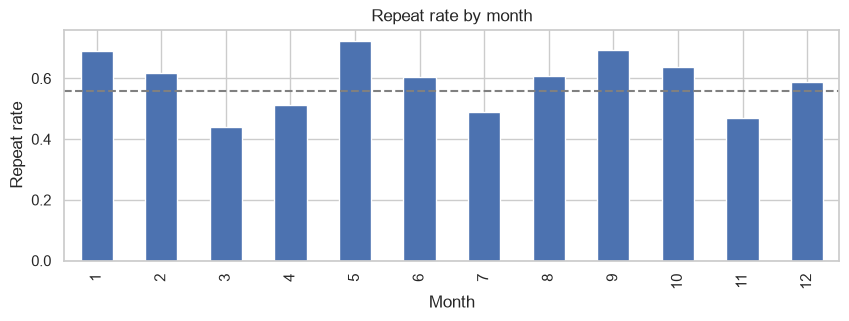

Month,1,2,3,4,5,6,7,8,9,10,11,12
Repeat rate per row,0.69,0.62,0.44,0.51,0.72,0.60,0.49,0.61,0.69,0.64,0.47,0.59
Repeat rate per customer,0.53,0.52,0.31,0.32,0.61,0.45,0.40,0.46,0.52,0.48,0.33,0.41


In [12]:
month = pd.to_datetime(X["purchase_date"]).dt.month    # month of each purchase
ratebymonth = y.groupby(month).mean()                  # repeat rate per month

ax = ratebymonth.plot(kind="bar", figsize=(10, 3))
ax.axhline(y.mean(), color="grey", linestyle="--")
ax.set(title="Repeat rate by month", xlabel="Month", ylabel="Repeat rate")
plt.show()

# average per customer instead of per row
percustomer = y.groupby([groups, month]).mean().groupby(level=1).mean()
pd.DataFrame({"Repeat rate per row": ratebymonth, "Repeat rate per customer": percustomer}).rename_axis("Month").round(2).T

In [13]:
year = pd.to_datetime(X["purchase_date"]).dt.year     # year of each purchase
early = year <= 2019                                  # first vs second half of the data

monthcheck = pd.DataFrame({
    "2015 to 2019": y[early].groupby(month[early]).mean(),
    "2020 to 2025": y[~early].groupby(month[~early]).mean(),
}).round(3).rename_axis("Month")
display(monthcheck)
print("Correlation of the two periods:", round(monthcheck["2015 to 2019"].corr(monthcheck["2020 to 2025"]), 2))

,2015 to 2019,2020 to 2025
Month,,
1,0.684,0.693
2,0.525,0.647
3,0.374,0.478
4,0.474,0.535
5,0.745,0.716
6,0.695,0.572
7,0.522,0.459
8,0.613,0.605
9,0.722,0.667


Correlation of the two periods: 0.81


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Repeat rate changes by month --> <b>0.44 in March</b> to <b>0.72 in May</b> (per customer 0.31 to 0.61)</li>
  <li>Pattern is <b>stable</b> over time (correlation 0.81) --> we keep the <b>month</b>, drop the <b>year</b></li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>3.2 One-hot encoding</h3>

</div>

In [14]:
# month as text (category, not number)
def addmonth(df):
    df = df.copy()
    df["month"] = pd.to_datetime(df["purchase_date"]).dt.strftime("%b")
    return df

CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "month"]
Xmonth = addmonth(X)

# one-hot, rare and unknown levels --> "infrequent"
encoder = OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False)
encoder.fit(Xmonth[CATEGORICAL].fillna("missing"))

# columns per variable
onehotnames = encoder.get_feature_names_out(CATEGORICAL)
encodingsummary = pd.DataFrame({
    "Levels": [Xmonth[col].nunique() for col in CATEGORICAL],
    "One hot columns": [sum(name.startswith(col + "_") for name in onehotnames) for col in CATEGORICAL],
}, index=[label(col) for col in CATEGORICAL]).rename_axis("Variable")
display(encodingsummary)
print("One hot columns in total:", len(onehotnames))

,Levels,One hot columns
Variable,,
Payment type,9,7
Salesperson,9,8
Commercial zone,5,4
Transport method,80,31
Month,12,12


One hot columns in total: 62


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>3.3 Decision</h3>

<table>
  <tr><th>Variable</th><th>Decision</th><th>Why</th></tr>
  <tr><td>Payment type, salesperson</td><td>one-hot</td><td>the repeat rate differs clearly between levels (Task 1, 8.3)</td></tr>
  <tr><td>Transport method</td><td>one-hot, rare levels grouped</td><td>80 levels, 51 with less than 30 rows (Task 1, 4.2) --> 31 columns (3.2)</td></tr>
  <tr><td>Commercial zone</td><td>one-hot</td><td>weak, but we keep it for now</td></tr>
  <tr><td>Warehouse</td><td>drop</td><td>99.7% one level (Task 1, 4.2)</td></tr>
  <tr><td>Document series</td><td>drop</td><td>no link with the target, only shows the time period (Task 1, 8.3 and 10)</td></tr>
  <tr><td>Purchase date</td><td>keep only the month</td><td>stable monthly pattern (3.1), the year is not useful for new data</td></tr>
</table>

</div>

<a id="clientes"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. The optional table clientes.csv</h2>

</div>

In [15]:
# add country_or_region and island_known from clientes
def joinclientes(df):
    extra = clientes[["customer_id", "country_or_region"]].copy()
    extra["island_known"] = clientes["island"].notna().astype(int)
    out = df.merge(extra, on="customer_id", how="left")
    out.index = df.index
    return out

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<ul>
<li>Only <b>country_or_region</b> and <b>island_known</b> are useful (Task 1, 6) --> joined by customer_id (left join)</li>
<li>Both are known at purchase time --> <b>no leakage</b></li>
</ul>

</div>

<a id="features"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Variables and new features</h2>

<h3>5.1 Supplied variables</h3>

<p><b>Decision</b></p>

<table>
<tr><th>Not used</th><th>Why</th></tr>
<tr><td>ID, random_noise</td><td>no signal (Task 1, 5.7)</td></tr>
<tr><td>customer_id</td><td>only for the join and the folds, the model would learn customers by heart</td></tr>
<tr><td>Total a Pagar, Total Bruto</td><td>can be calculated from other columns (Task 1, 5.5)</td></tr>
</table>

<p> --> All other columns are kept</p>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>5.2 New features</h3>

</div>

In [16]:
# new features from values of the same row
def addfeatures(df):
    df = df.copy()
    k = df["prior_purchase_count"]
    tenure = df["customer_tenure_days"]

    df["purchases_per_year"] = 0.0                                       # first purchase --> 0
    df.loc[tenure > 0, "purchases_per_year"] = k / (tenure / 365)        # purchases per year

    meangap = tenure / k.replace(0, np.nan)                              # rough days between purchases
    df["typical_gap_le_90"] = (meangap <= 90).astype(int)                # 1 = buys about every 90 days or more often

    df["discount_rate"] = ((df["Total Desc_ Linha"] + df["Total Desc_ Global"]) / df["Total Bruto"].replace(0, np.nan)).fillna(0)   # share of discount
    df["zero_cost"] = (df["Custo"] == 0).astype(int)                     # 1 = cost is 0
    df["has_shipping"] = (df["Total Portes"] > 0).astype(int)            # 1 = shipping paid
    return df

Xfeatures = addfeatures(Xfilled)

In [17]:
# new features next to the existing column they come from
comparison = pd.DataFrame({
    "New feature": ["purchases_per_year", "discount_rate", "zero_cost", "has_shipping", "typical_gap_le_90"],
    "Existing column": ["purchase_count_365d", "Total Desc_ Linha", "Custo", "Total Portes", "-"],
})

# AUC of each column
comparison["AUC new"] = [roc_auc_score(y, Xfeatures[col]) for col in comparison["New feature"]]
comparison["AUC existing"] = [roc_auc_score(y, Xfeatures[col]) if col != "-" else None for col in comparison["Existing column"]]

comparison.round(3)

,New feature,Existing column,AUC new,AUC existing
0,purchases_per_year,purchase_count_365d,0.744,0.753
1,discount_rate,Total Desc_ Linha,0.624,0.611
2,zero_cost,Custo,0.518,0.492
3,has_shipping,Total Portes,0.507,0.508
4,typical_gap_le_90,-,0.692,NaN


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">
<p><b>Insight</b></p>
<ul>
<li><b>Discount rate</b> (0.624) is a bit stronger than the line discount (0.611)</li>
<li><b>Purchases per year</b> (0.744) is close to purchase_count_365d (0.753) --> extra info about the whole customer time</li>
<li><b>Typical gap ≤ 90 days</b> (0.692) is strong on its own</li>
<li>Zero cost and has shipping are <b>weak</b> (~0.51) --> kept for now</li>
</ul>
</div>

<a id="scaling"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Scaling</h2>



</div>

In [18]:
NUMERIC = ["Total Liquido", "Total Imp_", "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo",
           "N_ Detalhes", "invoice_count_current_purchase",
           "days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count", "prior_total_spend",
           "prior_mean_purchase_value", "prior_std_purchase_value", "prior_min_purchase_value",
           "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days",
           "purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
           "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d"]

# log1p only works for values above -1 or -1
belowminusone = (Xfeatures[NUMERIC] <= -1).sum()
print("Columns with values of -1 or below:", (belowminusone > 0).sum())

skew = pd.DataFrame({"Skew before": Xfeatures[NUMERIC].skew(),
                     "Skew after log1p": np.log1p(Xfeatures[NUMERIC]).skew()})
print("Median absolute skew before:", round(skew["Skew before"].abs().median(), 2),
      " after:", round(skew["Skew after log1p"].abs().median(), 2))

# 8 most skewed columns
skew.index = skew.index.map(label)
skew.sort_values("Skew before", ascending=False).head(8).rename_axis("Variable").round(2)

Columns with values of -1 or below: 0
Median absolute skew before: 3.7  after: 0.99


,Skew before,Skew after log1p
Variable,,
Total Desc Global,27.46,9.28
Total Portes,19.55,2.27
Prior mean gap days,9.13,-1.02
Prior std gap days,7.87,-0.73
Days since previous purchase,6.67,-0.60
Invoice count current purchase,6.44,5.00
Prior min purchase value,6.15,-0.25
Total Desc Linha,5.92,0.24


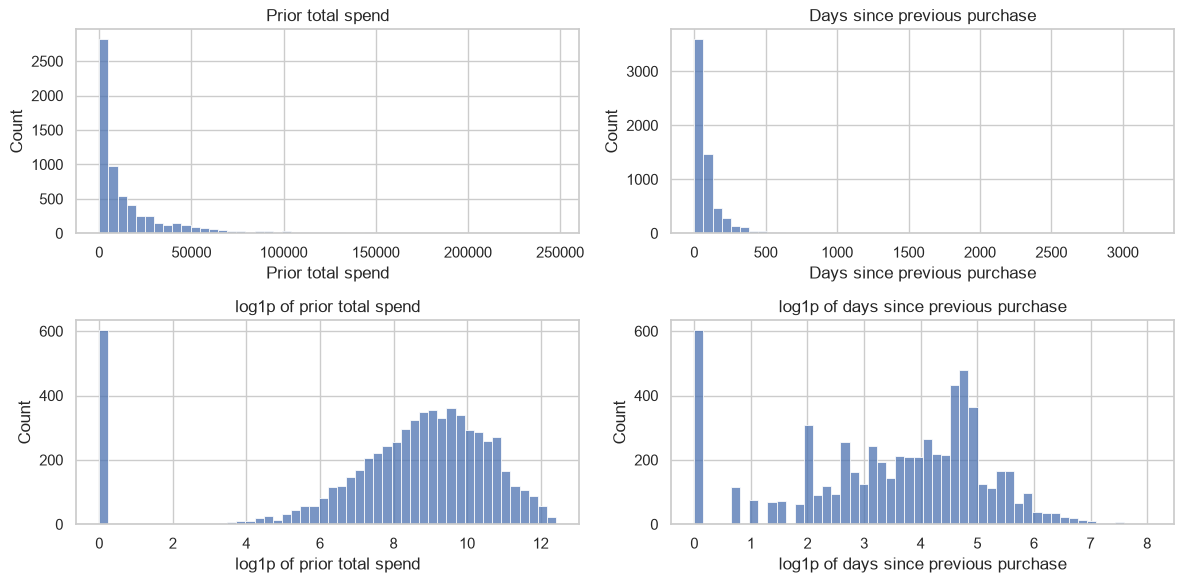

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, col in enumerate(["prior_total_spend", "days_since_previous_purchase"]):
    sns.histplot(Xfeatures[col], bins=50, ax=axes[0, j])
    axes[0, j].set(title=label(col), xlabel=label(col), ylabel="Count")
    sns.histplot(np.log1p(Xfeatures[col]), bins=50, ax=axes[1, j])
    axes[1, j].set(title="log1p of " + label(col).lower(), xlabel="log1p of " + label(col).lower(), ylabel="Count")
plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p><b>Insight</b></p><ul><li>Amounts are very skewed (Task 1, 4.1) --> log1p reduces the median skew from <b>3.7 to 0.99</b></li><li>Total Desc_ Global stays skewed because it is almost always <b>0</b>, the invoice count because it is almost always <b>1</b></li></ul></div>

<a id="pipeline"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>7. Pre-processing function and comparison</h2>

<h3>7.1 Pre-processing function</h3>



</div>

In [20]:
SCALERS = {"none": None, "standard": StandardScaler, "robust": RobustScaler, "minmax": MinMaxScaler}

# all pre-processing steps in one function
def foldmatrices(train, test, usemonth=True, usefeatures=True, useclientes=False, uselog=True, scaler="standard",
                 userepair=True, usestructural=True):
    numeric = list(NUMERIC)
    categorical = list(CATEGORICAL)
    if not usemonth:
        categorical.remove("month")
    flags = []

    # cleaning and new columns
    if userepair:
        train, test = repair(train), repair(test)
    if usestructural:
        train, test = fillstructural(train), fillstructural(test)
        flags += ["is_first_purchase", "has_gap_history"]
    train, test = addmonth(train), addmonth(test)
    if usefeatures:
        train, test = addfeatures(train), addfeatures(test)
        numeric += ["purchases_per_year", "discount_rate"]
        flags += ["typical_gap_le_90", "zero_cost", "has_shipping"]
    if useclientes:
        train, test = joinclientes(train), joinclientes(test)
        categorical += ["country_or_region"]
        flags += ["island_known"]

    # fill missing values (learned on train)
    train, test = fillmissing(train, test, [
        (numeric, SimpleImputer(strategy="median")),
        (categorical, SimpleImputer(strategy="constant", fill_value="missing")),
    ])

    numtrain = train[numeric].to_numpy(dtype=float)
    numtest = test[numeric].to_numpy(dtype=float)

    # log1p, not for discount_rate
    if uselog:
        logcols = [i for i, c in enumerate(numeric) if c != "discount_rate"]
        numtrain[:, logcols] = np.log1p(np.clip(numtrain[:, logcols], 0, None))
        numtest[:, logcols] = np.log1p(np.clip(numtest[:, logcols], 0, None))

    # scaling
    if SCALERS[scaler] is not None:
        fitted = SCALERS[scaler]().fit(numtrain)
        numtrain, numtest = fitted.transform(numtrain), fitted.transform(numtest)

    # one-hot
    encoder = OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False)
    cattrain = encoder.fit_transform(train[categorical])
    cattest = encoder.transform(test[categorical])

    # put everything together
    Atrain = np.hstack([numtrain, train[flags].to_numpy(dtype=float), cattrain])
    Atest = np.hstack([numtest, test[flags].to_numpy(dtype=float), cattest])
    return Atrain, Atest

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p>To check if our steps help, we compare with a <b>basic version</b> that only fills missing values, scales and one-hot encodes.</p></div>

In [21]:
# basic version: only fill missing values, scale and one-hot
BASICNUMERIC = NUMERIC + ["Total a Pagar", "Total Bruto"]
BASICCATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse", "document_series"]

def basicmatrices(train, test):
    train, test = fillmissing(train, test, [
        (BASICNUMERIC, SimpleImputer(strategy="median")),
        (BASICCATEGORICAL, SimpleImputer(strategy="constant", fill_value="missing")),
    ])

    sc = StandardScaler().fit(train[BASICNUMERIC])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train[BASICCATEGORICAL])

    Atrain = np.hstack([sc.transform(train[BASICNUMERIC]), enc.transform(train[BASICCATEGORICAL])])
    Atest = np.hstack([sc.transform(test[BASICNUMERIC]), enc.transform(test[BASICCATEGORICAL])])
    return Atrain, Atest

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>7.2 Comparison on held-out customers</h3>


</div>

In [22]:
# 5 folds by customer
splits = list(GroupKFold(n_splits=5).split(X, groups=groups))

models = {"Logistic Regression": LogisticRegression(max_iter=2000),
          "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOMSTATE)}

# AUC on the 5 folds
def heldoutauc(prepare, model):
    scores = []
    for trainidx, testidx in splits:
        Atrain, Atest = prepare(X.iloc[trainidx], X.iloc[testidx])
        model.fit(Atrain, y.iloc[trainidx])
        scores.append(roc_auc_score(y.iloc[testidx], model.predict_proba(Atest)[:, 1]))
    return np.array(scores)

In [23]:
# variants from basic to full pre-processing
variants = {
    "A basic": basicmatrices,
    "B cleaned": lambda tr, te: foldmatrices(tr, te, usemonth=False, usefeatures=False),
    "C B + month": lambda tr, te: foldmatrices(tr, te, usefeatures=False),
    "D C + new features": lambda tr, te: foldmatrices(tr, te),
    "E D + clientes": lambda tr, te: foldmatrices(tr, te, useclientes=True),
}

scores = {}
for name, prepare in variants.items():
    for modelname, model in models.items():
        scores[(name, modelname)] = heldoutauc(prepare, model)

pd.Series({key: s.mean() for key, s in scores.items()}).unstack().rename_axis(index="Variant", columns="Model").round(4)

Model,Decision Tree,Logistic Regression
Variant,,
A basic,0.7388,0.7742
B cleaned,0.7327,0.7809
C B + month,0.7377,0.7884
D C + new features,0.7463,0.7883
E D + clientes,0.7517,0.7885


In [24]:
# fold by fold
names = list(variants)
for modelname in models:
    print(modelname)
    for before, after in zip(names, names[1:]):
        diff = scores[(after, modelname)] - scores[(before, modelname)]
        print(f"  {after[:1]} vs {before[:1]}: {diff.mean():+.4f}, better in {(diff > 0).sum()} of 5 folds")

Logistic Regression
  B vs A: +0.0067, better in 5 of 5 folds
  C vs B: +0.0075, better in 5 of 5 folds
  D vs C: -0.0001, better in 2 of 5 folds
  E vs D: +0.0001, better in 3 of 5 folds
Decision Tree
  B vs A: -0.0060, better in 2 of 5 folds
  C vs B: +0.0050, better in 4 of 5 folds
  D vs C: +0.0086, better in 3 of 5 folds
  E vs D: +0.0054, better in 2 of 5 folds


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p><b>Insight</b></p><ul><li><b>Cleaning</b> helps, mostly the logistic regression (+0.0067, all 5 folds)</li><li><b>Month</b> helps the most (+0.0075 / +0.0056, all 5 folds) --> kept</li><li><b>New features</b> and <b>clientes</b> change almost nothing --> new features kept for now, clientes not used</li></ul></div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p>B adds several steps at once --> we remove <b>one step at a time</b> to see which one matters</p></div>

In [25]:
# B without one step each
withoutstep = {
    "B cleaned": {},
    "B without repair": {"userepair": False},
    "B without structural fill and flags": {"usestructural": False},
    "B without log1p": {"uselog": False},
}
rows = {}
for name, switches in withoutstep.items():
    for modelname, model in models.items():
        s = heldoutauc(lambda tr, te: foldmatrices(tr, te, usemonth=False, usefeatures=False, **switches), model)
        base = scores[("B cleaned", modelname)]
        rows[(name, modelname)] = f"{s.mean():.4f} ({s.mean() - base.mean():+.4f}, better in {(s > base).sum()} of 5)"
pd.Series(rows).unstack().rename_axis(index="Variant", columns="Model")

Model,Decision Tree,Logistic Regression
Variant,,
B cleaned,"0.7327 (+0.0000, better in 0 of 5)","0.7809 (+0.0000, better in 0 of 5)"
B without log1p,"0.7328 (+0.0000, better in 1 of 5)","0.7740 (-0.0069, better in 0 of 5)"
B without repair,"0.7443 (+0.0115, better in 3 of 5)","0.7804 (-0.0005, better in 2 of 5)"
B without structural fill and flags,"0.7449 (+0.0121, better in 4 of 5)","0.7802 (-0.0007, better in 1 of 5)"


In [26]:
scaling = {}
for scaler in ["none", "standard", "robust", "minmax"]:
    for withlog in [False, True]:
        s = heldoutauc(lambda tr, te: foldmatrices(tr, te, uselog=withlog, scaler=scaler),
                         models["Logistic Regression"])
        scaling[(scaler.capitalize(), "With log1p" if withlog else "Without log1p")] = s.mean()

pd.Series(scaling).unstack().rename_axis(index="Scaler", columns="Transform").round(4)

Transform,With log1p,Without log1p
Scaler,,
Minmax,0.7893,0.7862
None,0.7883,0.7613
Robust,0.7884,0.7874
Standard,0.7883,0.7873


In [27]:
# without log1p and scaler: does the model finish?
Atr, Ava = foldmatrices(X.iloc[splits[0][0]], X.iloc[splits[0][1]], uselog=False, scaler="none")
lbfgs = LogisticRegression(max_iter=2000).fit(Atr, y.iloc[splits[0][0]])
print("Iterations used in fold 1:", lbfgs.n_iter_[0], "of 2000")

Iterations used in fold 1: 2000 of 2000


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p><b>Insight</b></p><ul><li><b>log1p</b> matters most for the logistic regression (-0.0069 without it, worse in all 5 folds)</li><li>Repair and flags change little --> <b>kept</b>, because they make the data correct</li><li>With log1p all scalers are between <b>0.7883 and 0.7893</b> --> we keep the <b>StandardScaler</b></li><li>Without log1p and scaler the model <b>does not converge</b> (2000 of 2000 iterations, AUC 0.7586) --> scaling is needed</li></ul></div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>7.3 Check over time</h3>


</div>

In [28]:
# sort by date, then train on the past and test on the next part 
order = pd.to_datetime(X["purchase_date"]).sort_values(kind="stable").index
Xtime, ytime = X.loc[order], y.loc[order]

rows = {}
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(Xtime), start=1):
    for name in ["B cleaned", "C B + month", "D C + new features", "E D + clientes"]:
        Atr, Ava = variants[name](Xtime.iloc[tr], Xtime.iloc[va])
        model = LogisticRegression(max_iter=2000).fit(Atr, ytime.iloc[tr])
        rows[(fold, name)] = roc_auc_score(ytime.iloc[va], model.predict_proba(Ava)[:, 1])

# gain of each step per fold
timescores = pd.Series(rows).unstack()
gains = pd.DataFrame({"Month (C vs B)": timescores["C B + month"] - timescores["B cleaned"],
                      "New features (D vs C)": timescores["D C + new features"] - timescores["C B + month"],
                      "Clientes (E vs D)": timescores["E D + clientes"] - timescores["D C + new features"]})
gains.loc["Mean"] = gains.mean()
gains.rename_axis("Fold").round(4)

,Month (C vs B),New features (D vs C),Clientes (E vs D)
Fold,,,
1,0.0047,0.0002,0.0042
2,-0.0059,0.0007,0.0019
3,0.0078,0.0005,0.0004
4,-0.0061,-0.0047,0.0028
5,0.0134,0.0002,-0.0006
Mean,0.0028,-0.0006,0.0017


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><p><b>Insight</b></p><ul><li><b>Month</b> also helps on later data (+0.0028 on average)</li><li><b>New features</b> change nothing over time (-0.0006)</li><li><b>Clientes</b> adds very little (+0.0017 over time, +0.0001 on the customer folds) --> <b>not used</b></li></ul></div>

<a id="sklearn_pipeline"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><h2>8. Pipeline in preprocessing.py</h2></div>

In [29]:
# pipeline from preprocessing.py with the same columns
flags = ["is_first_purchase", "has_gap_history", "typical_gap_le_90", "zero_cost", "has_shipping"]
pipeline = preprocessor(NUMERIC + ["purchases_per_year", "discount_rate"], flags, CATEGORICAL)

# same fold, once with foldmatrices and once with the pipeline
trainidx, validx = splits[0]
Afoldtrain, Afoldval = foldmatrices(X.iloc[trainidx], X.iloc[validx])
Apipetrain = pipeline.fit_transform(X.iloc[trainidx])
Apipeval = pipeline.transform(X.iloc[validx])

# both the same?
pd.Series({
    "Columns": Apipetrain.shape[1],
    "Column names": len(pipeline.named_steps["columns"].get_feature_names_out()),
    "Largest difference train": np.abs(Afoldtrain - Apipetrain).max(),
    "Largest difference validation": np.abs(Afoldval - Apipeval).max(),
}, name="Value", dtype=object).rename_axis("Check").to_frame()

,Value
Check,
Columns,90
Column names,90
Largest difference train,0.0
Largest difference validation,0.0


<a id="cleaninglog"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;"><h2>9. Cleaning log</h2></div>

In [30]:
# rows changed by each step
problems = countproblems(X)
meanchanged = ((Xrepaired["prior_mean_purchase_value"] - X["prior_mean_purchase_value"]).abs() > 0.02) | \
              (X["prior_mean_purchase_value"].isna() & Xrepaired["prior_mean_purchase_value"].notna())
spendchanged = ~((X["spend_365d"] == Xrepaired["spend_365d"]) | (X["spend_365d"].isna() & Xrepaired["spend_365d"].isna()))
structural = list(NEEDED) + ["spend_365d"]
structuralfilled = (Xrepaired[structural].isna() & Xfilled[structural].notna()).any(axis=1)
stillmissing = Xfilled[NUMERIC + CATEGORICAL[:-1]].isna().any(axis=1)

# record every decision 
cleaninglog = CleaningLog("everything and then some, train.csv")
cleaninglog.record("all columns", "dropped the empty rows from train", "no feature value, nothing to learn, rows in test are never dropped",
                   empty.sum(), carries={"dropempty": True})
cleaninglog.record("days_since_previous_purchase, prior_mean_gap_days", "-4 to missing", "-4 days is a code, not a real number of days",
                   problems["Day code of minus 4"], carries={"tomissing": "below 0"})
cleaninglog.record("prior_mean_purchase_value", "recomputed as prior_total_spend / prior_purchase_count", "wrong, negative or 1e9 values, the mean follows from total and count",
                   meanchanged.sum(), carries={"formula": "prior_total_spend / prior_purchase_count"})
cleaninglog.record("prior_max_purchase_value", "values above the total spend to missing", "a single purchase can not be bigger than the total",
                   problems["Max above total"], carries={"bound": "prior_total_spend"})
cleaninglog.record("spend_365d", "1e9 to missing, absolute value, above the total to missing", "placeholder, wrong sign and impossible values",
                   spendchanged.sum(), carries={"placeholder": 1e8, "absolute": True, "bound": "prior_total_spend"})
cleaninglog.record("history columns", "0 when not enough earlier purchases, plus two flags", "the value can not exist yet, so the gap is structural",
                   structuralfilled.sum(), carries={"needed": NEEDED, "flags": ["is_first_purchase", "has_gap_history"]})
cleaninglog.record("other missing values", "training median for numbers, level missing for categories", "few and random, fitted on the training rows only",
                   stillmissing.sum(), carries={"numeric": "median", "categorical": "missing"})
cleaninglog.record("prior_total_spend", "IQR outliers kept, log1p instead", "real big customers, they repeat more often",
                   outlier.sum(), carries={"dropoutliers": False})
cleaninglog.record("warehouse, document_series, Total a Pagar, Total Bruto, random_noise", "not used", "almost constant, only some years, can be computed or only noise",
                   0, carries={"dropped": ["warehouse", "document_series", "Total a Pagar", "Total Bruto", "random_noise"]})
cleaninglog.record("purchase_date", "month as a category, year dropped", "stable monthly pattern, later purchases fall into unseen years",
                   len(X), carries={"extract": "month"})
cleaninglog.record("clientes.csv", "not used", "the two columns add far less than the spread between the folds",
                   0, carries={"useclientes": False})
cleaninglog.record("new features", "purchases_per_year, typical_gap_le_90, discount_rate, zero_cost, has_shipping", "built from the same row only, kept for now",
                   len(X), carries={"newfeatures": ["purchases_per_year", "typical_gap_le_90", "discount_rate", "zero_cost", "has_shipping"]})
cleaninglog.record("numeric and categorical columns", "log1p and StandardScaler, one-hot with minimum frequency 30", "less skew for the logistic regression, rare levels grouped",
                   len(X), carries={"numeric": NUMERIC + ["purchases_per_year", "discount_rate"], "flags": flags,
                                    "categorical": CATEGORICAL, "log1p": True, "scaler": "standard", "minfrequency": 30})

# save the log
Path("logs").mkdir(exist_ok=True)
cleaninglog.to_json("logs/task2_cleaning_log.json")
print("Decisions saved:", len(cleaninglog.records()))

Decisions saved: 13
